# Praktikum Supervised Learning
## Klasifikasi Steel Plates Faults

### Tujuan
1. Memahami karakteristik dataset Steel Plates Faults.
2. Melakukan preprocessing data untuk klasifikasi.
3. Membandingkan lima algoritma supervised learning.
4. Mengevaluasi model menggunakan accuracy, precision, recall, dan Macro F1-Score.
5. Menentukan model terbaik berdasarkan hasil evaluasi.
6. Menganalisis confusion matrix dan feature importance.
7. Menyimpan model terpilih untuk integrasi dengan aplikasi web Kelompok 3.

### Algoritma
- Decision Tree
- Random Forest
- K-Nearest Neighbors (KNN)
- Logistic Regression
- Gaussian Naive Bayes

Dataset yang digunakan adalah `fault.csv`.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print("Library berhasil diimpor.")

Library berhasil diimpor.


### Penjelasan Cell 1 — Import Library

Library yang digunakan mencakup Pandas dan NumPy untuk pengolahan data, Matplotlib dan Seaborn untuk visualisasi, serta Scikit-learn untuk preprocessing, pelatihan, dan evaluasi model.

Lima algoritma klasifikasi akan dibandingkan menggunakan pembagian data dan metrik evaluasi yang sama agar hasilnya adil.

Pipeline digunakan untuk menggabungkan imputasi missing value dan standardisasi dengan model klasifikasi.

In [2]:
DATA_PATH = Path.cwd() / "faults.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH.resolve()}\n"
        "Pastikan fault.csv berada satu folder dengan notebook."
    )

# Mencoba separator umum; file CSV standar akan terbaca pada percobaan pertama.
try:
    df = pd.read_csv(DATA_PATH)
    if df.shape[1] == 1:
        df_alt = pd.read_csv(DATA_PATH, sep=";")
        if df_alt.shape[1] > 1:
            df = df_alt
except Exception:
    df = pd.read_csv(DATA_PATH, sep=";")

df.columns = df.columns.astype(str).str.strip()
print("Lokasi dataset:", DATA_PATH.resolve())
print("Ukuran dataset:", df.shape)
display(df.head())

Lokasi dataset: C:\Users\Mutia\Downloads\The-Bujang-Kelompok-3-dev\faults.csv
Ukuran dataset: (1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


### Penjelasan Cell 2 — Load Dataset

Dataset dibaca menggunakan fungsi `pd.read_csv()`.

Notebook memeriksa keberadaan file sebelum membaca data. Selanjutnya ditampilkan dimensi dataset dan lima baris pertama untuk memastikan proses pembacaan berhasil.

Nama kolom dibersihkan dari spasi di bagian awal dan akhir agar memudahkan pemrosesan berikutnya.

In [3]:
# CELL 3 - PEMERIKSAAN STRUKTUR DATA

print("DAFTAR KOLOM")
for nomor, kolom in enumerate(df.columns, start=1):
    print(f"{nomor}. {kolom}")

print("\nTIPE DATA")
display(df.dtypes.to_frame("Tipe Data"))

print("\nMISSING VALUE")
display(
    df.isna().sum()
      .to_frame("Jumlah Missing")
      .query("`Jumlah Missing` > 0")
)

print("\nSTATISTIK DESKRIPTIF")
display(df.describe(include="all").T)

print("\nJUMLAH BARIS DUPLIKAT")
print(df.duplicated().sum())

DAFTAR KOLOM
1. X_Minimum
2. X_Maximum
3. Y_Minimum
4. Y_Maximum
5. Pixels_Areas
6. X_Perimeter
7. Y_Perimeter
8. Sum_of_Luminosity
9. Minimum_of_Luminosity
10. Maximum_of_Luminosity
11. Length_of_Conveyer
12. TypeOfSteel_A300
13. TypeOfSteel_A400
14. Steel_Plate_Thickness
15. Edges_Index
16. Empty_Index
17. Square_Index
18. Outside_X_Index
19. Edges_X_Index
20. Edges_Y_Index
21. Outside_Global_Index
22. LogOfAreas
23. Log_X_Index
24. Log_Y_Index
25. Orientation_Index
26. Luminosity_Index
27. SigmoidOfAreas
28. Pastry
29. Z_Scratch
30. K_Scatch
31. Stains
32. Dirtiness
33. Bumps
34. Other_Faults

TIPE DATA


,Tipe Data
X_Minimum,int64
X_Maximum,int64
Y_Minimum,int64
Y_Maximum,int64
Pixels_Areas,int64
X_Perimeter,int64
Y_Perimeter,int64
Sum_of_Luminosity,int64
Minimum_of_Luminosity,int64
Maximum_of_Luminosity,int64



MISSING VALUE


,Jumlah Missing



STATISTIK DESKRIPTIF


,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,5.711360e+02,5.206907e+02,0.0000,51.0000,4.350000e+02,1.053000e+03,1.705000e+03
X_Maximum,1941.0,6.179645e+02,4.976274e+02,4.0000,192.0000,4.670000e+02,1.072000e+03,1.713000e+03
Y_Minimum,1941.0,1.650685e+06,1.774578e+06,6712.0000,471253.0000,1.204128e+06,2.183073e+06,1.298766e+07
Y_Maximum,1941.0,1.650739e+06,1.774590e+06,6724.0000,471281.0000,1.204136e+06,2.183084e+06,1.298769e+07
Pixels_Areas,1941.0,1.893878e+03,5.168460e+03,2.0000,84.0000,1.740000e+02,8.220000e+02,1.526550e+05
X_Perimeter,1941.0,1.118552e+02,3.012092e+02,2.0000,15.0000,2.600000e+01,8.400000e+01,1.044900e+04
Y_Perimeter,1941.0,8.296600e+01,4.264829e+02,1.0000,13.0000,2.500000e+01,8.300000e+01,1.815200e+04
Sum_of_Luminosity,1941.0,2.063121e+05,5.122936e+05,250.0000,9522.0000,1.920200e+04,8.301100e+04,1.159141e+07
Minimum_of_Luminosity,1941.0,8.454869e+01,3.213428e+01,0.0000,63.0000,9.000000e+01,1.060000e+02,2.030000e+02
Maximum_of_Luminosity,1941.0,1.301937e+02,1.869099e+01,37.0000,124.0000,1.270000e+02,1.400000e+02,2.530000e+02



JUMLAH BARIS DUPLIKAT
0


### Penjelasan Cell 3 — Pemeriksaan Struktur Data

Tahap ini bertujuan memahami struktur dataset sebelum pelatihan model.

Pemeriksaan mencakup nama kolom, tipe data, missing value, statistik deskriptif, dan jumlah baris duplikat.

Informasi ini digunakan untuk menentukan kolom target dan fitur input yang tepat. Kolom target harus berupa label jenis kecacatan, sedangkan fitur input berisi karakteristik yang digunakan untuk memprediksi label.

Baris duplikat tidak langsung dihapus karena perlu dipastikan terlebih dahulu apakah merupakan duplikasi yang tidak disengaja atau observasi yang memang valid.

In [4]:

import numpy as np
import pandas as pd

# Nama kolom target yang menunjukkan jenis cacat
target_cols = [
    "Pastry",
    "Z_Scratch",
    "K_Scatch",
    "Stains",
    "Dirtiness",
    "Bumps",
    "Other_Faults"
]

# Pastikan seluruh kolom target tersedia
missing_targets = [col for col in target_cols if col not in df.columns]

if missing_targets:
    raise ValueError(f"Kolom target tidak ditemukan: {missing_targets}")

# Periksa jumlah label aktif pada setiap baris
jumlah_label = df[target_cols].sum(axis=1)

print("Distribusi jumlah label aktif per baris:")
display(jumlah_label.value_counts().sort_index())

# Setiap baris harus memiliki tepat satu label aktif
if not jumlah_label.eq(1).all():
    raise ValueError(
        "Ada baris dengan jumlah label aktif bukan 1. "
        "Periksa kolom target sebelum melanjutkan."
    )

# Ubah one-hot encoding menjadi satu label kelas
y = df[target_cols].idxmax(axis=1)

# Gunakan 27 kolom lainnya sebagai fitur
X = df.drop(columns=target_cols)

print("Jumlah data:", len(df))
print("Jumlah fitur:", X.shape[1])
print("Jumlah kelas target:", y.nunique())
print("Nama kelas:", sorted(y.unique()))

display(y.value_counts().rename("Jumlah data"))


Distribusi jumlah label aktif per baris:


1    1941
Name: count, dtype: int64

Jumlah data: 1941
Jumlah fitur: 27
Jumlah kelas target: 7
Nama kelas: ['Bumps', 'Dirtiness', 'K_Scatch', 'Other_Faults', 'Pastry', 'Stains', 'Z_Scratch']


Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: Jumlah data, dtype: int64

Cell 4 — Menentukan fitur dan target
Tujuan: Memisahkan kolom fitur (X) dan target (y). Tujuh kolom jenis cacat masih berbentuk one-hot encoding, sehingga kita ubah menjadi satu label kelas agar bisa digunakan oleh model klasifikasi multikelas.

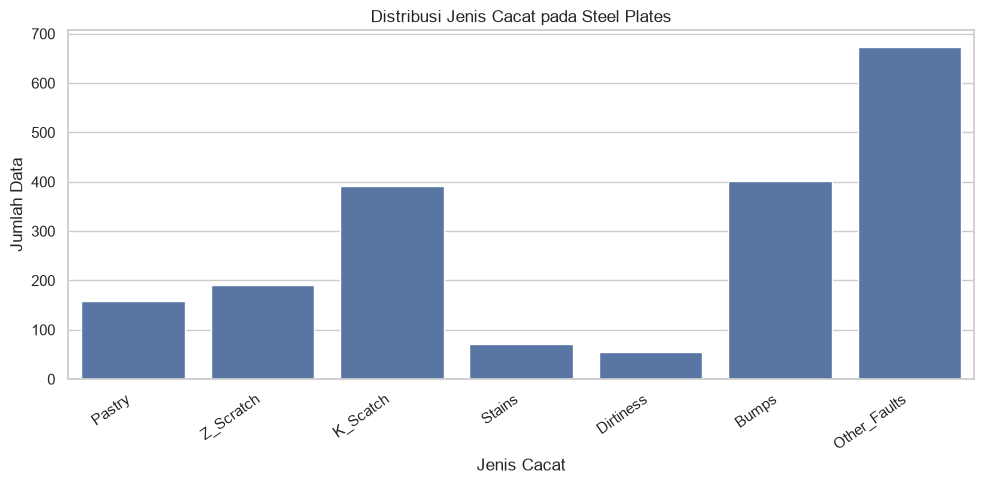

Proporsi setiap kelas:


Pastry          0.081
Z_Scratch       0.098
K_Scatch        0.201
Stains          0.037
Dirtiness       0.028
Bumps           0.207
Other_Faults    0.347
Name: count, dtype: float64

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

jumlah_kelas = y.value_counts().reindex(target_cols, fill_value=0)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=jumlah_kelas.index,
    y=jumlah_kelas.values
)

plt.title("Distribusi Jenis Cacat pada Steel Plates")
plt.xlabel("Jenis Cacat")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Proporsi setiap kelas:")
display((jumlah_kelas / jumlah_kelas.sum()).round(3))


Cell 5 — Visualisasi distribusi kelas
Tujuan: Mengetahui jumlah data untuk setiap jenis cacat. Informasi ini penting karena jumlah tiap kelas bisa berbeda jauh.

In [6]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("Jumlah fitur:", X_train.shape[1])

print("\nProporsi kelas pada data training:")
display(y_train.value_counts(normalize=True).round(3))

print("\nProporsi kelas pada data testing:")
display(y_test.value_counts(normalize=True).round(3))


Jumlah data training: 1552
Jumlah data testing: 389
Jumlah fitur: 27

Proporsi kelas pada data training:


Other_Faults    0.347
Bumps           0.207
K_Scatch        0.202
Z_Scratch       0.098
Pastry          0.081
Stains          0.037
Dirtiness       0.028
Name: proportion, dtype: float64


Proporsi kelas pada data testing:


Other_Faults    0.347
Bumps           0.208
K_Scatch        0.201
Z_Scratch       0.098
Pastry          0.082
Stains          0.036
Dirtiness       0.028
Name: proportion, dtype: float64

Cell 6 — Membagi data training dan testing
Tujuan: Menyediakan data untuk melatih model dan data terpisah untuk mengevaluasi kemampuannya pada data yang belum dilihat.

In [7]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Gaussian Naive Bayes": make_pipeline(
        StandardScaler(),
        GaussianNB()
    )
}

print("Model yang akan diuji:")
for nama in models:
    print("-", nama)


Model yang akan diuji:
- Decision Tree
- Random Forest
- KNN
- Logistic Regression
- Gaussian Naive Bayes


Cell 7 — Membuat model supervised learning
Kita akan membandingkan lima algoritma: Decision Tree, Random Forest, K-Nearest Neighbors (KNN), Logistic Regression, dan Gaussian Naive Bayes. Untuk model yang sensitif terhadap skala fitur, kita menggunakan standardisasi melalui StandardScaler.

In [8]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

hasil_model = []
trained_models = {}

for nama, model in models.items():
    print(f"Melatih model: {nama}")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    trained_models[nama] = model

    hasil_model.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

hasil_df = pd.DataFrame(hasil_model)
hasil_df = hasil_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("Hasil evaluasi model:")
display(hasil_df.round(4))


Melatih model: Decision Tree
Melatih model: Random Forest
Melatih model: KNN
Melatih model: Logistic Regression
Melatih model: Gaussian Naive Bayes
Hasil evaluasi model:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest,0.8046,0.8684,0.7949,0.8264
1,KNN,0.7275,0.7458,0.7482,0.7416
2,Decision Tree,0.7069,0.7250,0.7138,0.7148
3,Logistic Regression,0.6452,0.6115,0.7311,0.6365
4,Gaussian Naive Bayes,0.6093,0.6333,0.7169,0.6339


Cell 8 — Melatih dan mengevaluasi model
Tujuan: Melatih kelima model menggunakan data training, lalu membandingkan hasil prediksi pada data testing.

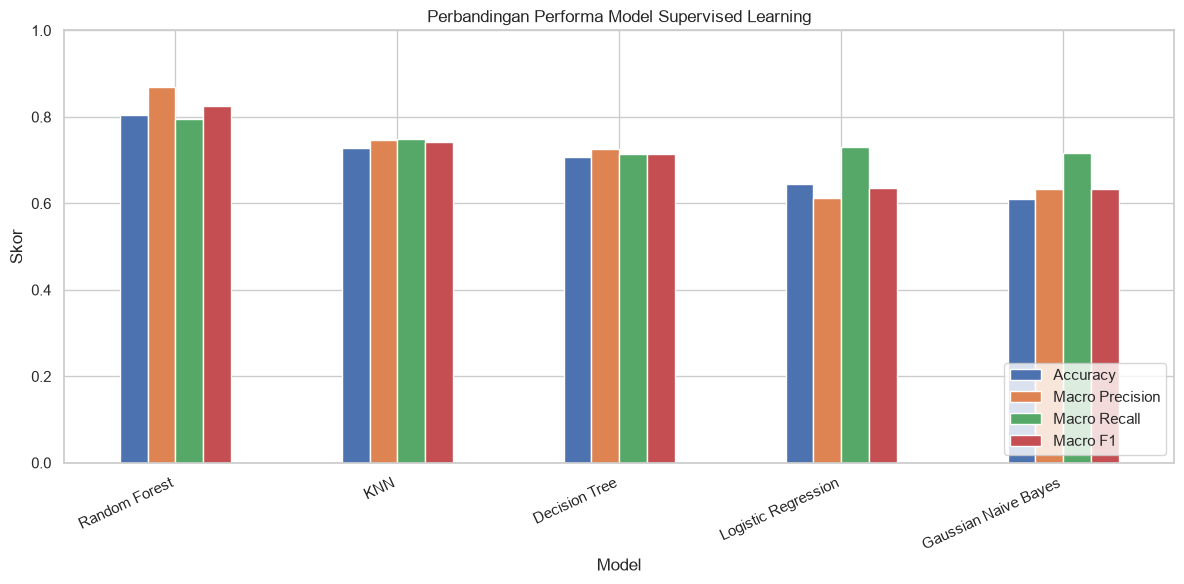

In [9]:

hasil_plot = hasil_df.set_index("Model")[
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
]

ax = hasil_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

ax.set_title("Perbandingan Performa Model Supervised Learning")
ax.set_xlabel("Model")
ax.set_ylabel("Skor")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Cell 9 — Visualisasi perbandingan model

Penjelasan: Grafik ini memudahkan perbandingan performa kelima algoritma. Model dengan Accuracy tertinggi belum tentu memiliki Macro F1 tertinggi, sehingga pemilihan model terbaik pada notebook ini didasarkan pada Macro F1.

In [10]:

best_name = hasil_df.loc[0, "Model"]
best_model = trained_models[best_name]
y_pred_best = best_model.predict(X_test)

print("Model terbaik berdasarkan Macro F1:", best_name)
print(
    "Macro F1:",
    round(f1_score(
        y_test, y_pred_best, average="macro", zero_division=0
    ), 4)
)
print(
    "Accuracy:",
    round(accuracy_score(y_test, y_pred_best), 4)
)


Model terbaik berdasarkan Macro F1: Random Forest
Macro F1: 0.8264
Accuracy: 0.8046


Cell 10 — Menentukan model terbaik

In [11]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_best,
        labels=target_cols,
        zero_division=0,
        digits=4
    )
)


              precision    recall  f1-score   support

      Pastry     0.6522    0.4688    0.5455        32
   Z_Scratch     0.9706    0.8684    0.9167        38
    K_Scatch     0.9861    0.9103    0.9467        78
      Stains     1.0000    0.8571    0.9231        14
   Dirtiness     1.0000    0.9091    0.9524        11
       Bumps     0.7671    0.6914    0.7273        81
Other_Faults     0.7030    0.8593    0.7733       135

    accuracy                         0.8046       389
   macro avg     0.8684    0.7949    0.8264       389
weighted avg     0.8142    0.8046    0.8042       389



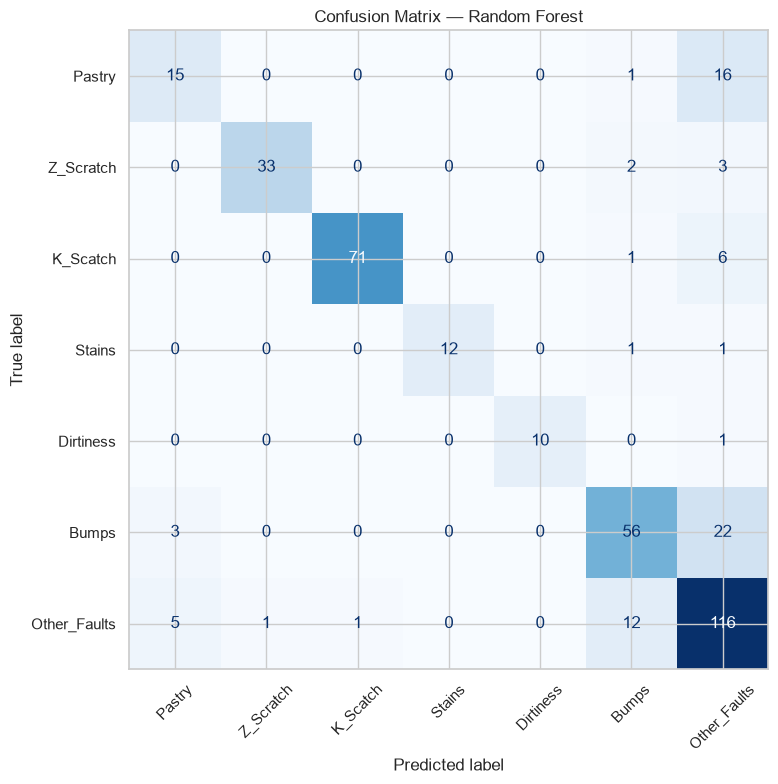

In [12]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=target_cols
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_cols
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()


In [13]:

best_row = hasil_df.iloc[0]

print("KESIMPULAN SUPERVISED LEARNING")
print("=" * 40)
print(f"Jumlah data: {len(df)}")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Jumlah kelas: {y.nunique()}")
print(f"Model terbaik: {best_row['Model']}")
print(f"Accuracy: {best_row['Accuracy']:.4f}")
print(f"Macro Precision: {best_row['Macro Precision']:.4f}")
print(f"Macro Recall: {best_row['Macro Recall']:.4f}")
print(f"Macro F1: {best_row['Macro F1']:.4f}")

print("\nInterpretasi:")
print(
    f"Berdasarkan Macro F1 pada data testing, "
    f"model {best_row['Model']} memperoleh skor tertinggi "
    "di antara model yang diuji."
)
print(
    "Gunakan classification report dan confusion matrix "
    "untuk menjelaskan performa masing-masing jenis cacat."
)


KESIMPULAN SUPERVISED LEARNING
Jumlah data: 1941
Jumlah fitur: 27
Jumlah kelas: 7
Model terbaik: Random Forest
Accuracy: 0.8046
Macro Precision: 0.8684
Macro Recall: 0.7949
Macro F1: 0.8264

Interpretasi:
Berdasarkan Macro F1 pada data testing, model Random Forest memperoleh skor tertinggi di antara model yang diuji.
Gunakan classification report dan confusion matrix untuk menjelaskan performa masing-masing jenis cacat.
